# 02 — EEG Preprocessing (all 34 recordings)

**Project:** EEG Attention State Detection (Focused / Unfocused / Drowsy)

This notebook turns the raw `.mat` recordings into clean, labeled, model-ready data. It builds directly on what
notebook 01 established (and on the official dataset documentation):

| Fact | Source |
|---|---|
| `o.data` is `(n_samples, 25)`, sampling rate 128 Hz | notebook 01 + Kaggle docs |
| EEG = columns 4:17 (14 channels: AF3 F7 F3 FC5 T7 P7 O1 O2 P8 T8 FC6 F4 F8 AF4) | Kaggle docs |
| Other columns: counter, interpolated flag, contact quality, gyro, timestamps, markers | Kaggle docs |
| `tag` is empty and `marker` is a sparse pulse, so **labels are not in the files** | notebook 01 |
| Labels come from the protocol: ~first 10 min focused, next 10 min unfocused, remainder drowsy | Aci, Kaya, Mishchenko (2019) |

### Pipeline

```
raw .mat  ->  QC (all files)  ->  channel selection  ->  time-based labels
          ->  band-pass filter  ->  windowing + bad-window detection
          ->  robust per-recording scaling  ->  save (continuous signal + window table)
```

### Design decisions (all tunable in the config cell)

- **No random window splitting anywhere.** This notebook only *prepares* data. Train/test splitting must be by subject
  (or at least by recording) and happens later.
- **Filtering is done on the whole continuous recording**, before windowing, to avoid edge effects on every window.
- **Normalization is per recording and uses only that recording's own statistics**, so nothing leaks between train and test.
- **Windows are not materialized on disk.** We save the continuous signal and a window index table (start, label, keep/reject
  reason). Later notebooks slice windows on the fly. This avoids storing ~2x duplicated overlapping data.
- **Artifact thresholds are relative** (multiples of each channel's own median), because we do not want to rely on the device
  units.

> Things this notebook can *not* settle by itself: which recording belongs to which participant, and how exact the 10/20-minute
> label boundaries are in practice. Both are flagged where they matter.

## 0. Imports

In [1]:
import json
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import butter, sosfiltfilt, welch

try:
    from tqdm.auto import tqdm
except ImportError:  # tqdm is optional
    def tqdm(x, **kwargs):
        return x

plt.rcParams["figure.figsize"] = (14, 4)

c:\Users\gaida\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

Everything you may want to change is here. Nothing below hard-codes these values.

In [2]:
# ------------------------------------------------------------------ paths
DATASET_PATH = Path(os.environ.get(
    "EEG_DATASET_PATH",
    r"C:\Users\gaida\.cache\kagglehub\datasets\inancigdem\eeg-data-for-mental-attention-state-detection\versions\1",
))
EEG_DIR = DATASET_PATH / "EEG Data" / "EEG Data"      # deepest folder = 34 unique files (no duplicates)

PROJECT_ROOT = Path("..").resolve()                   # this notebook lives in notebooks/
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CONT_DIR = PROCESSED_DIR / "continuous"
for d in (INTERIM_DIR, PROCESSED_DIR, CONT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ dataset layout (from the Kaggle documentation)
EXPECTED_N_RECORDINGS = 34
FS_EXPECTED = 128
N_COLUMNS = 25
EEG_COL_SLICE = slice(3, 17)          # Python 0-indexed == documentation channels 4:17
COL_COUNTER, COL_INTERP, COL_CQ = 0, 1, 2
EEG_NAMES = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]

# ------------------------------------------------------------------ labels (time-based protocol)
LABEL_NAMES = {0: "focused", 1: "unfocused", 2: "drowsy"}
FOCUSED_END_MIN = 10.0                # 0-10 min   -> focused
UNFOCUSED_END_MIN = 20.0              # 10-20 min  -> unfocused ; 20 min-end -> drowsy

# ------------------------------------------------------------------ filtering
HP_HZ = 1.0                           # removes slow drift
LP_HZ = 45.0                          # removes high-frequency noise and 50 Hz mains
FILTER_ORDER = 4

# ------------------------------------------------------------------ channel selection
# None = choose automatically from the QC table (section 3). Or force a list, e.g. ["F7", "F3", "P7", "O1", "O2", "P8", "AF4"].
ACTIVE_CHANNELS_OVERRIDE = None
MIN_ACTIVE_FRACTION = 0.8             # a channel must be non-flat in at least this fraction of recordings

# ------------------------------------------------------------------ windowing and bad-window rules
WIN_SEC = 2.0
STEP_SEC = 1.0                        # 50 % overlap
EDGE_TRIM_SEC = 2.0                   # filter edge effects at the start/end of each recording
PTP_K = 5.0                           # reject window if any channel peak-to-peak > K x that channel's median window peak-to-peak
FLAT_REL = 0.05                       # reject window if any channel std < FLAT_REL x that channel's median window std
REJECT_PACKET_GAPS = True             # reject windows overlapping a jump in the device packet counter

# ------------------------------------------------------------------ sanity plots
N_PSD_RECORDINGS = 10                 # how many recordings to use for the per-class spectrum check
N_PSD_WINDOWS_PER_CLASS = 40
RANDOM_SEED = 42

## 2. Find the recordings and define loaders

We sort **numerically** (`record1, record2, ... record34`). Notebook 01 used alphabetical order (`record1, record10, record11...`),
which is confusing for anything time-related.

In [3]:
def rec_number(path: Path) -> int:
    return int(re.search(r"(\d+)", path.stem).group(1))


mat_files = sorted(EEG_DIR.glob("*.mat"), key=rec_number)
print(f"Recordings found: {len(mat_files)}   (first: {mat_files[0].name}, last: {mat_files[-1].name})")
if len(mat_files) != EXPECTED_N_RECORDINGS:
    warnings.warn(f"Expected {EXPECTED_N_RECORDINGS} recordings, found {len(mat_files)}. Check EEG_DIR.")


def load_recording(path: Path) -> dict:
    """Load one .mat file and return the raw (n_samples, 25) matrix plus metadata."""
    o = sio.loadmat(path)["o"][0, 0]
    raw = np.asarray(o["data"], dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != N_COLUMNS:
        raise ValueError(f"{path.name}: expected (n, {N_COLUMNS}) data, got {raw.shape}")
    fs = float(np.squeeze(o["sampFreq"]))
    if fs != FS_EXPECTED:
        warnings.warn(f"{path.name}: sampling rate {fs} Hz (expected {FS_EXPECTED})")
    return {
        "name": path.name,
        "stem": path.stem,
        "num": rec_number(path),
        "id": str(np.squeeze(o["id"])),
        "fs": fs,
        "raw": raw,
    }

Recordings found: 34   (first: eeg_record1.mat, last: eeg_record34.mat)


## 3. Quality control across all recordings (first pass)

For each recording we compute:

- **duration**, and whether it is long enough for the 10 + 10 min protocol,
- **packet jumps**: forward jumps in the counter column, which suggest dropped packets (approximate; the counter wraps, so we
  only count forward jumps > 1),
- **interpolated fraction**: share of samples flagged as interpolated by the device,
- **per-channel standard deviation** (DC removed), used to detect flat (dead / unused) electrodes.

In [4]:
qc_rows, std_rows = [], []

for path in tqdm(mat_files, desc="QC pass"):
    rec = load_recording(path)
    raw = rec["raw"]
    eeg = raw[:, EEG_COL_SLICE]

    qc_rows.append({
        "file": rec["name"],
        "num": rec["num"],
        "id": rec["id"],
        "fs": rec["fs"],
        "n_samples": len(raw),
        "duration_min": round(len(raw) / rec["fs"] / 60, 2),
        "counter_max": raw[:, COL_COUNTER].max(),
        "packet_jumps": int(np.sum(np.diff(raw[:, COL_COUNTER]) > 1)),
        "interpolated_frac": float(np.mean(raw[:, COL_INTERP] != 0)),
        "mean_cq": float(raw[:, COL_CQ].mean()),
    })
    std_rows.append(pd.Series(eeg.std(axis=0), index=EEG_NAMES, name=rec["name"]))
    del rec, raw, eeg

qc_df = pd.DataFrame(qc_rows)
std_df = pd.DataFrame(std_rows)
qc_df.to_csv(INTERIM_DIR / "qc_summary.csv", index=False)
std_df.to_csv(INTERIM_DIR / "channel_std_per_recording.csv")
display(qc_df)

QC pass: 100%|██████████| 34/34 [00:06<00:00,  5.39it/s]


,file,num,id,fs,n_samples,duration_min,counter_max,packet_jumps,interpolated_frac,mean_cq
0,eeg_record1.mat,1,201410092013.D091BB44,128.0,308868,40.22,128.0,1,0.000000,100.425661
1,eeg_record2.mat,2,201410101933.D091BB44,128.0,366020,47.66,128.0,1,0.000000,103.104251
2,eeg_record3.mat,3,201410121914.D091BB44,128.0,357224,46.51,128.0,0,0.000000,100.339199
3,eeg_record4.mat,4,201410131955.D091BB44,128.0,380344,49.52,128.0,0,0.000000,97.764258
4,eeg_record5.mat,5,201410211925.D091BB44,128.0,351204,45.73,128.0,3,0.000014,89.549911
5,eeg_record6.mat,6,201411241923.D091BB44,128.0,288752,37.60,128.0,276,0.000021,149.117339
6,eeg_record7.mat,7,201411251929.D091BB44,128.0,398816,51.93,128.0,0,0.000000,101.881800
7,eeg_record8.mat,8,201411272109.D091BB44,128.0,365888,47.64,128.0,76,0.000005,100.437410
8,eeg_record9.mat,9,201411301931.D091BB44,128.0,388788,50.62,128.0,1,0.000000,89.964271
9,eeg_record10.mat,10,201412021859.D091BB44,128.0,381340,49.65,128.0,0,0.000000,102.959312


In [5]:
short = qc_df[qc_df["duration_min"] <= UNFOCUSED_END_MIN]
print(f"Recordings shorter than {UNFOCUSED_END_MIN:.0f} min (no drowsy segment possible): {len(short)}")
print(f"Duration range: {qc_df['duration_min'].min():.1f} to {qc_df['duration_min'].max():.1f} min")
print(f"Recordings with packet jumps: {(qc_df['packet_jumps'] > 0).sum()}   (max jumps in one file: {qc_df['packet_jumps'].max()})")
print(f"Recordings with any interpolated samples: {(qc_df['interpolated_frac'] > 0).sum()}")

Recordings shorter than 20 min (no drowsy segment possible): 0
Duration range: 27.9 to 63.0 min
Recordings with packet jumps: 15   (max jumps in one file: 276)
Recordings with any interpolated samples: 8


### 3.1 Which EEG channels actually carry signal?

In record 1 several channels looked flat while others carried real signal. We check whether that holds across **all** files.
The heatmap shows log10 of each channel's standard deviation per recording. Look for columns that are consistently dark.

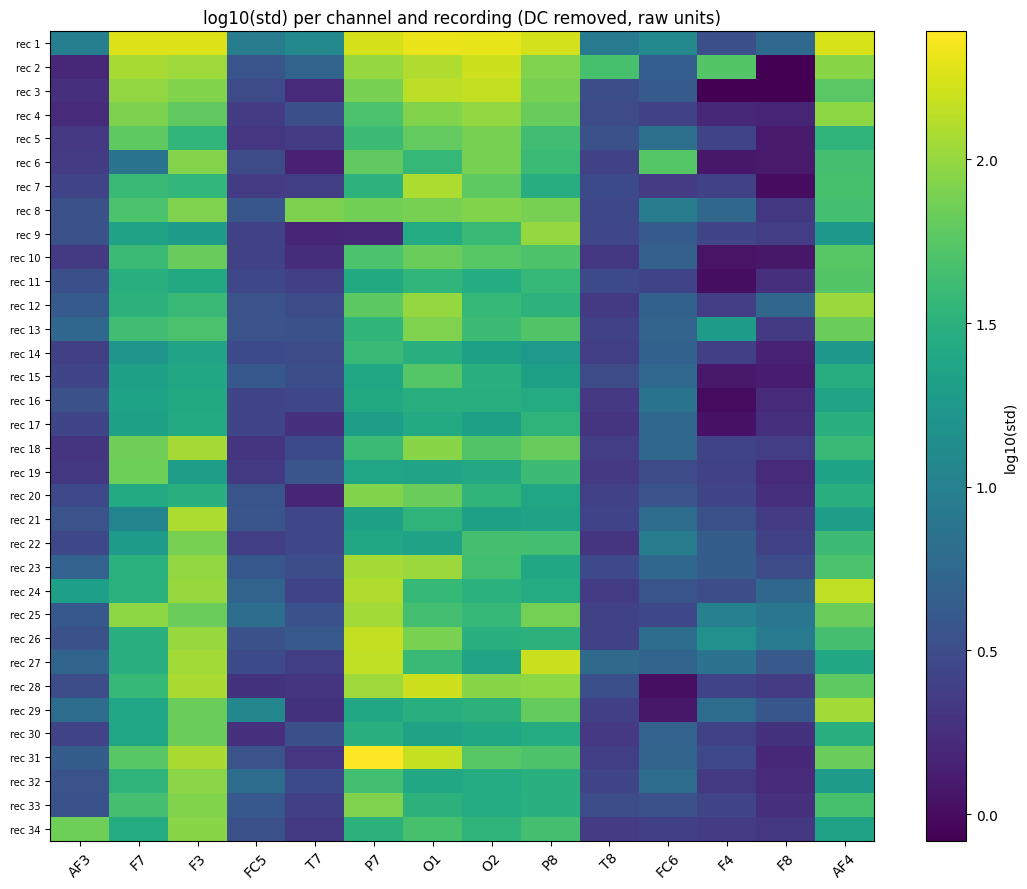

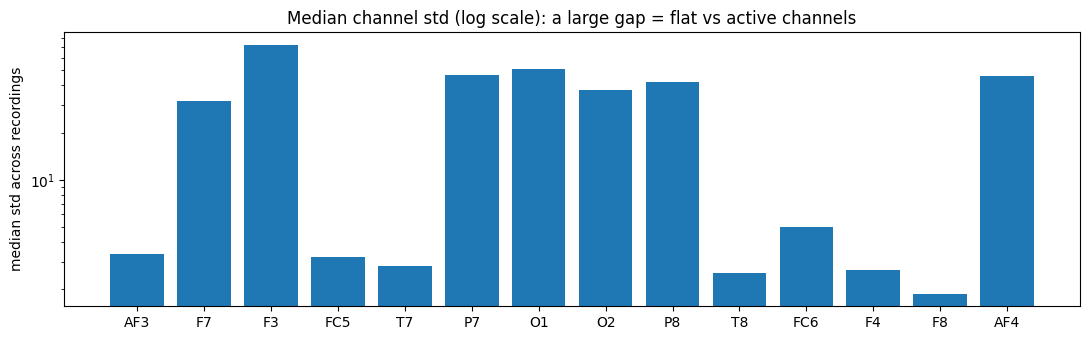

In [6]:
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(np.log10(std_df.values + 1e-3), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(EEG_NAMES)))
ax.set_xticklabels(EEG_NAMES, rotation=45)
ax.set_yticks(range(len(std_df)))
ax.set_yticklabels([f"rec {n}" for n in qc_df["num"]], fontsize=7)
ax.set_title("log10(std) per channel and recording (DC removed, raw units)")
plt.colorbar(im, ax=ax, label="log10(std)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))
med = std_df.median()
ax.bar(EEG_NAMES, med.values)
ax.set_yscale("log")
ax.set_ylabel("median std across recordings")
ax.set_title("Median channel std (log scale): a large gap = flat vs active channels")
plt.tight_layout()
plt.show()

In [7]:
def auto_flat_threshold(values, min_ratio=3.0):
    """Split 'flat' from 'active' at the largest gap in log10(std). Returns 0.0 if there is no clear gap."""
    v = np.sort(np.asarray(values, dtype=float).ravel())
    v = v[v > 0]
    if len(v) < 2:
        return 0.0
    logv = np.log10(v)
    gaps = np.diff(logv)
    i = int(gaps.argmax())
    if gaps[i] >= np.log10(min_ratio):
        return float(10 ** ((logv[i] + logv[i + 1]) / 2))
    return 0.0


FLAT_STD_THRESHOLD = auto_flat_threshold(std_df.values)
active_frac = (std_df > FLAT_STD_THRESHOLD).mean()
print(f"Auto flat/active std threshold: {FLAT_STD_THRESHOLD:.3f} (0.0 means no clear gap was found)\n")
print("Fraction of recordings in which each channel is active:")
print(active_frac.round(2).to_string())

if ACTIVE_CHANNELS_OVERRIDE is not None:
    ACTIVE_CHANNELS = list(ACTIVE_CHANNELS_OVERRIDE)
    print("\nUsing MANUAL channel list.")
else:
    ACTIVE_CHANNELS = [c for c in EEG_NAMES if active_frac[c] >= MIN_ACTIVE_FRACTION]

assert len(ACTIVE_CHANNELS) > 0, "No active channels selected. Inspect the heatmap and set ACTIVE_CHANNELS_OVERRIDE."
active_idx = [EEG_NAMES.index(c) for c in ACTIVE_CHANNELS]
print(f"\nSelected {len(ACTIVE_CHANNELS)} channels: {ACTIVE_CHANNELS}")

Auto flat/active std threshold: 0.000 (0.0 means no clear gap was found)

Fraction of recordings in which each channel is active:
AF3    1.0
F7     1.0
F3     1.0
FC5    1.0
T7     1.0
P7     1.0
O1     1.0
O2     1.0
P8     1.0
T8     1.0
FC6    1.0
F4     1.0
F8     1.0
AF4    1.0

Selected 14 channels: ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']


> **Check this before trusting the rest.** If the selected list does not match what the heatmap shows, set
> `ACTIVE_CHANNELS_OVERRIDE` in the config cell and re-run. The automatic rule is a convenience, not ground truth.
> If a channel is active in some recordings and flat in others, look at its column in the heatmap and decide deliberately.

## 4. Labels

The files contain no per-sample label, so we derive it from elapsed time following the recording protocol
(focused, then unfocused, then drowsy). Two caveats:

1. The boundaries are protocol times, not individually verified states. A participant may already be drowsy before minute 20
   or still alert after it. Treat labels as *noisy but principled*.
2. The drowsy segment is "the remainder", so its length differs a lot between recordings (see the plot). Class balance will be
   uneven and drowsy will dominate.

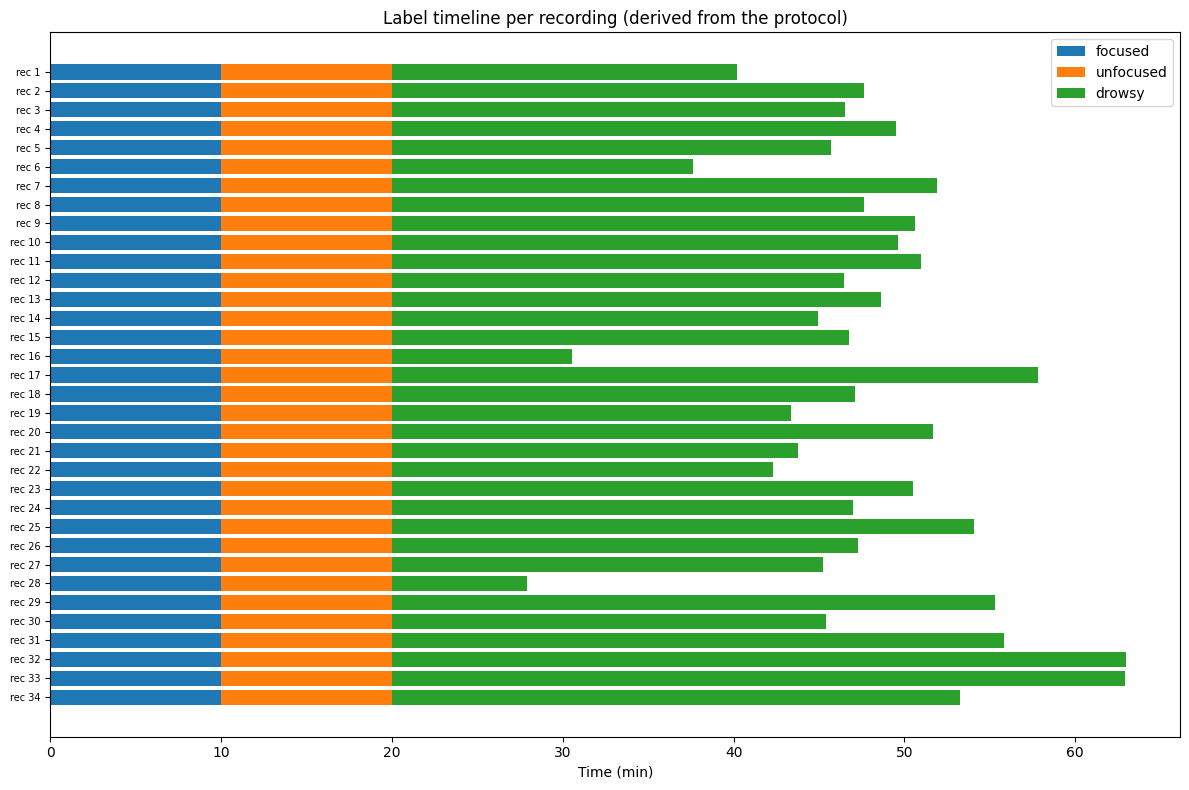

Total time  focused: 340 min | unfocused: 340 min | drowsy: 949 min


In [8]:
def build_sample_labels(n_samples: int, fs: float) -> np.ndarray:
    """0 = focused, 1 = unfocused, 2 = drowsy, assigned per sample from elapsed time."""
    t_min = np.arange(n_samples) / fs / 60.0
    labels = np.full(n_samples, 2, dtype=np.int8)
    labels[t_min < UNFOCUSED_END_MIN] = 1
    labels[t_min < FOCUSED_END_MIN] = 0
    return labels


focused = np.minimum(qc_df["duration_min"], FOCUSED_END_MIN)
unfocused = np.clip(qc_df["duration_min"] - FOCUSED_END_MIN, 0, UNFOCUSED_END_MIN - FOCUSED_END_MIN)
drowsy = np.clip(qc_df["duration_min"] - UNFOCUSED_END_MIN, 0, None)

fig, ax = plt.subplots(figsize=(12, 8))
y = np.arange(len(qc_df))
ax.barh(y, focused, label="focused")
ax.barh(y, unfocused, left=focused, label="unfocused")
ax.barh(y, drowsy, left=focused + unfocused, label="drowsy")
ax.set_yticks(y)
ax.set_yticklabels([f"rec {n}" for n in qc_df["num"]], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Time (min)")
ax.set_title("Label timeline per recording (derived from the protocol)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Total time  focused: {focused.sum():.0f} min | unfocused: {unfocused.sum():.0f} min | drowsy: {drowsy.sum():.0f} min")

## 5. Filtering

We apply, on the whole continuous recording and per channel:

1. remove the DC offset (the ~4200 baseline seen in the raw data),
2. a zero-phase Butterworth band-pass, 1 to 45 Hz.

Zero-phase (`sosfiltfilt`) is fine here because processing is offline. It would not be valid for a real-time system.
Let's first look at what it does on record 1.

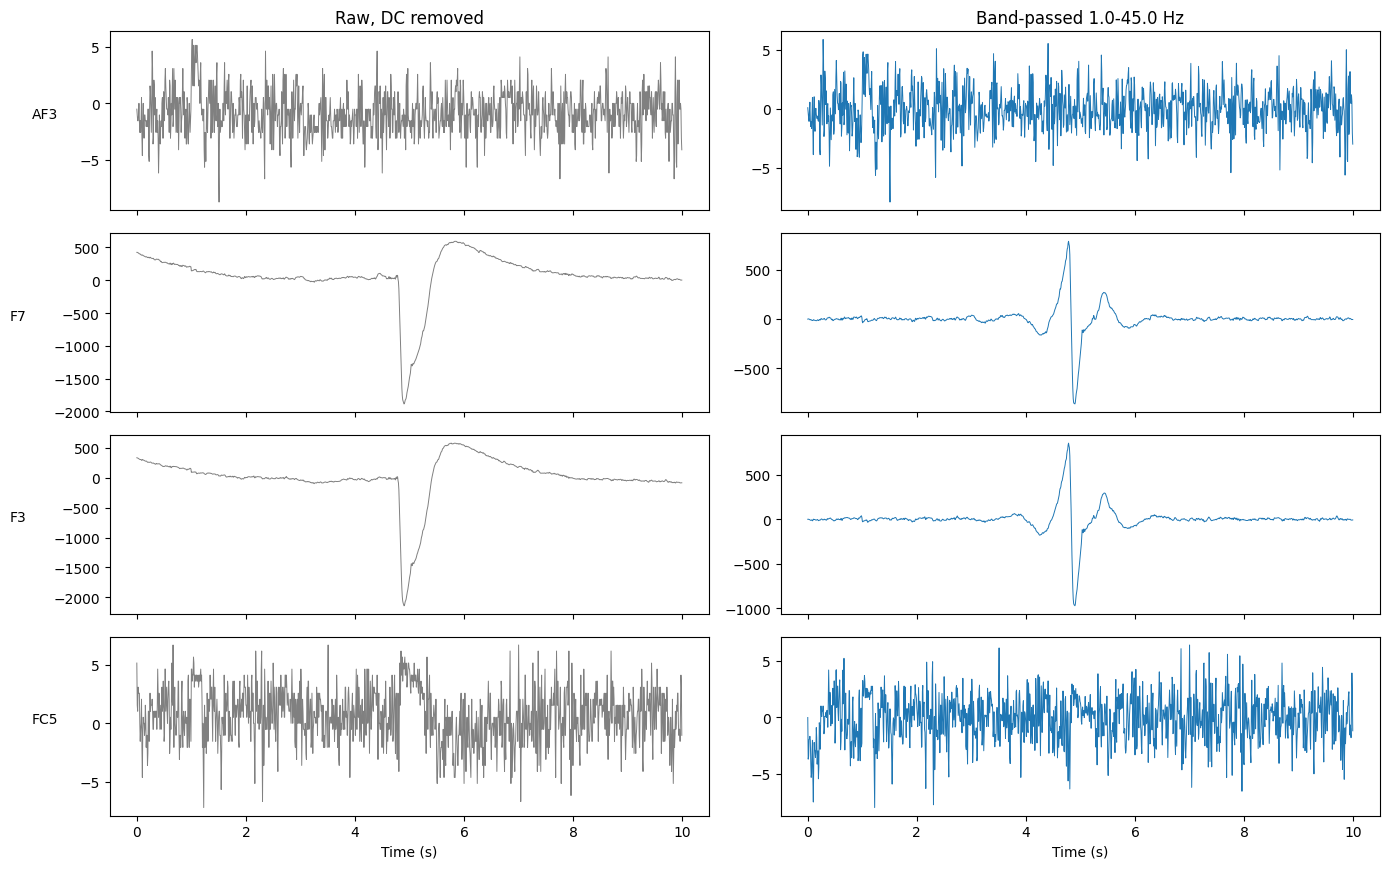

In [9]:
def bandpass_filter(x, fs, lo=HP_HZ, hi=LP_HZ, order=FILTER_ORDER):
    """x: (n_samples, n_channels). Returns the DC-removed, band-passed signal."""
    sos = butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x - np.median(x, axis=0), axis=0)


demo = load_recording(mat_files[0])
fs_demo = demo["fs"]
eeg_demo = demo["raw"][:, EEG_COL_SLICE][:, active_idx]
eeg_demo_dc = eeg_demo - np.median(eeg_demo, axis=0)
eeg_demo_f = bandpass_filter(eeg_demo, fs_demo)

seconds = 10
n_show = int(seconds * fs_demo)
t = np.arange(n_show) / fs_demo
n_ch_show = min(4, len(ACTIVE_CHANNELS))

fig, axes = plt.subplots(n_ch_show, 2, figsize=(14, 2.2 * n_ch_show), sharex=True)
axes = np.atleast_2d(axes)
for i in range(n_ch_show):
    axes[i, 0].plot(t, eeg_demo_dc[:n_show, i], lw=0.7, color="gray")
    axes[i, 1].plot(t, eeg_demo_f[:n_show, i], lw=0.7)
    axes[i, 0].set_ylabel(ACTIVE_CHANNELS[i], rotation=0, labelpad=25)
axes[0, 0].set_title("Raw, DC removed")
axes[0, 1].set_title(f"Band-passed {HP_HZ}-{LP_HZ} Hz")
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

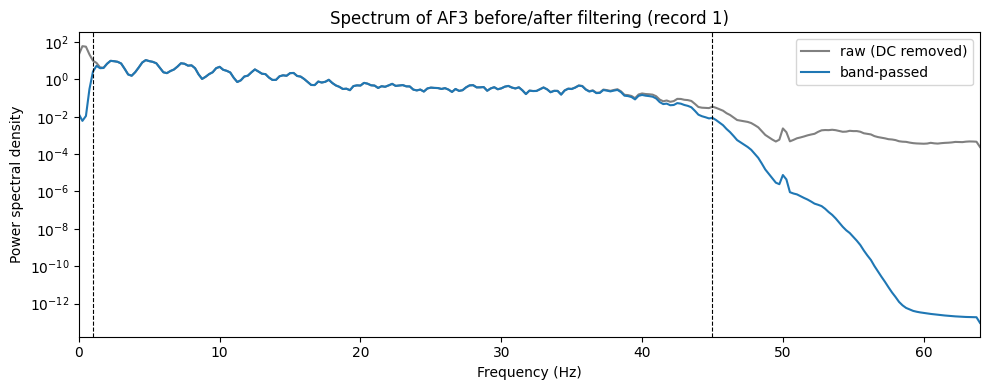

In [10]:
# Power spectrum before/after, first active channel, whole recording
f_raw, p_raw = welch(eeg_demo_dc[:, 0], fs=fs_demo, nperseg=int(4 * fs_demo))
f_flt, p_flt = welch(eeg_demo_f[:, 0], fs=fs_demo, nperseg=int(4 * fs_demo))

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f_raw, p_raw, label="raw (DC removed)", color="gray")
ax.semilogy(f_flt, p_flt, label="band-passed")
ax.axvline(HP_HZ, ls="--", c="k", lw=0.8)
ax.axvline(LP_HZ, ls="--", c="k", lw=0.8)
ax.set_xlim(0, fs_demo / 2)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power spectral density")
ax.set_title(f"Spectrum of {ACTIVE_CHANNELS[0]} before/after filtering (record {demo['num']})")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Windowing and bad-window detection

We cut the filtered signal into overlapping windows (`WIN_SEC` long, every `STEP_SEC`). Each window gets one label and is
either kept or rejected with a **reason**:

| Reason | Rule |
|---|---|
| `edge` | window touches the first/last `EDGE_TRIM_SEC` seconds (filter edge effects) |
| `boundary` | window straddles two label segments (would have a mixed label) |
| `packet_gap` | window overlaps a jump in the device packet counter |
| `flat` | some channel's std is far below its own typical value (signal lost) |
| `artifact` | some channel's peak-to-peak is far above its own typical value (movement, blinks, electrode pops) |

Artifact and flat thresholds are **relative to each channel's own median window statistic in that recording**, so they do not
depend on the device units.

In [11]:
def compute_window_table(x, labels, gap_mask, fs):
    """x: filtered (n_samples, n_channels). Returns a DataFrame with one row per window."""
    win = int(round(WIN_SEC * fs))
    step = int(round(STEP_SEC * fs))
    n = len(x)
    starts = np.arange(0, n - win + 1, step)
    ends = starts + win                                  # exclusive

    w = sliding_window_view(x, win, axis=0)[::step]      # (n_windows, n_channels, win) as a view, no copy
    ptp = w.max(axis=-1) - w.min(axis=-1)
    sd = w.std(axis=-1)

    ref_ptp = np.median(ptp, axis=0)
    ref_sd = np.median(sd, axis=0)
    artifact = (ptp > PTP_K * ref_ptp).any(axis=1)
    flat = (sd < FLAT_REL * ref_sd).any(axis=1)

    boundary = labels[starts] != labels[ends - 1]        # labels are monotone in time, so equal ends = same label inside
    trim = int(round(EDGE_TRIM_SEC * fs))
    edge = (starts < trim) | (ends > n - trim)

    if REJECT_PACKET_GAPS:
        cs = np.concatenate([[0], np.cumsum(gap_mask)])
        gap = (cs[ends] - cs[starts]) > 0
    else:
        gap = np.zeros(len(starts), dtype=bool)

    reason = np.select(
        [edge, boundary, gap, flat, artifact],
        ["edge", "boundary", "packet_gap", "flat", "artifact"],
        default="ok",
    )
    return pd.DataFrame({
        "start": starts,
        "end": ends,
        "t_start_s": starts / fs,
        "label": labels[starts].astype(int),
        "max_ptp_ratio": (ptp / ref_ptp).max(axis=1),
        "reason": reason,
        "keep": reason == "ok",
    })


def packet_gap_mask(counter):
    mask = np.zeros(len(counter), dtype=bool)
    mask[np.where(np.diff(counter) > 1)[0] + 1] = True
    return mask


# ---- demo on record 1
labels_demo = build_sample_labels(len(eeg_demo_f), fs_demo)
tbl_demo = compute_window_table(eeg_demo_f, labels_demo, packet_gap_mask(demo["raw"][:, COL_COUNTER]), fs_demo)
print(tbl_demo["reason"].value_counts().to_string())
print(f"\nKept {tbl_demo['keep'].mean():.1%} of {len(tbl_demo)} windows")

reason
ok          2154
artifact     176
flat          76
edge           4
boundary       2

Kept 89.3% of 2412 windows


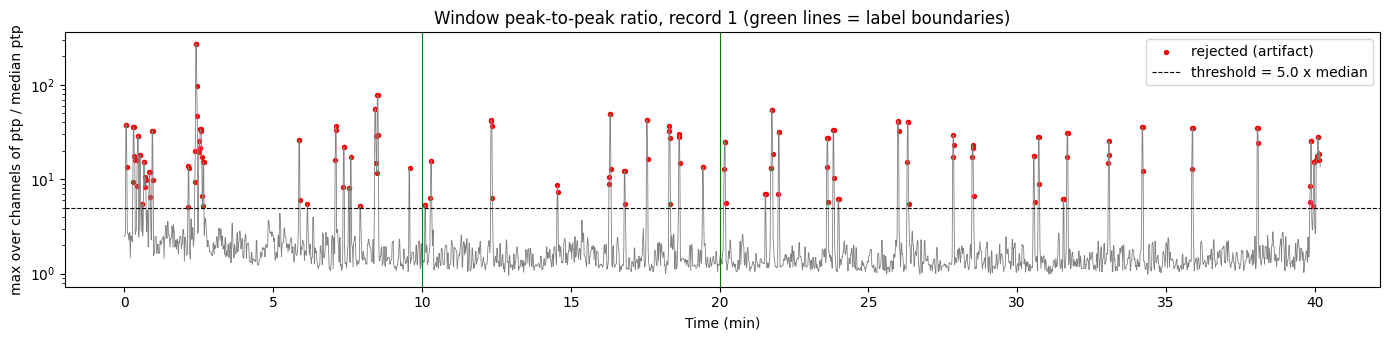

In [12]:
# Where are the flagged windows in time? (record 1, worst-channel peak-to-peak ratio)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(tbl_demo["t_start_s"] / 60, tbl_demo["max_ptp_ratio"], lw=0.6, color="gray")
bad = tbl_demo[tbl_demo["reason"] == "artifact"]
ax.scatter(bad["t_start_s"] / 60, bad["max_ptp_ratio"], s=8, color="red", label="rejected (artifact)")
ax.axhline(PTP_K, ls="--", c="k", lw=0.8, label=f"threshold = {PTP_K} x median")
ax.axvline(FOCUSED_END_MIN, c="green", lw=0.8)
ax.axvline(UNFOCUSED_END_MIN, c="green", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("Time (min)")
ax.set_ylabel("max over channels of ptp / median ptp")
ax.set_title(f"Window peak-to-peak ratio, record {demo['num']} (green lines = label boundaries)")
ax.legend()
plt.tight_layout()
plt.show()

If the artifact rate looks far too high or far too low (see the summary later), tune `PTP_K` in the config. The visible movement
artifact near 4.8 s in record 1 should be among the flagged windows.

## 7. Scaling and the full per-recording pipeline

Each recording is standardized **per channel with a robust z-score** (median and MAD, computed from that recording only). MAD is
used instead of std so the large artifacts do not inflate the scale. Because the statistics come only from the recording itself,
nothing is shared across recordings, so there is no train/test leakage from this step.

The processed continuous signal is saved as `float32` in `data/processed/continuous/`.

In [13]:
def robust_zscore(x):
    med = np.median(x, axis=0)
    mad = np.median(np.abs(x - med), axis=0)
    return (x - med) / (1.4826 * mad + 1e-8)


def process_recording(path: Path, save: bool = True) -> pd.DataFrame:
    rec = load_recording(path)
    fs, raw = rec["fs"], rec["raw"]

    eeg = raw[:, EEG_COL_SLICE][:, active_idx]
    x = bandpass_filter(eeg, fs)
    labels = build_sample_labels(len(x), fs)
    gap_mask = packet_gap_mask(raw[:, COL_COUNTER])

    table = compute_window_table(x, labels, gap_mask, fs)
    table.insert(0, "recording", rec["name"])
    table.insert(1, "rec_num", rec["num"])

    if save:
        np.savez(
            CONT_DIR / f"{rec['stem']}.npz",
            signal=robust_zscore(x).astype(np.float32),
            labels=labels,
            channels=np.array(ACTIVE_CHANNELS),
            fs=fs,
            rec_id=rec["id"],
        )
    return table

## 8. Run on all recordings

In [14]:
tables = [process_recording(p) for p in tqdm(mat_files, desc="Preprocessing")]
windows = pd.concat(tables, ignore_index=True)

# Until the subject mapping is known (section 10), the grouping unit is the recording.
windows["group"] = windows["recording"]

windows.to_csv(PROCESSED_DIR / "windows.csv", index=False)
with open(PROCESSED_DIR / "preprocessing_config.json", "w") as f:
    json.dump({
        "active_channels": ACTIVE_CHANNELS, "fs": FS_EXPECTED,
        "hp_hz": HP_HZ, "lp_hz": LP_HZ, "filter_order": FILTER_ORDER,
        "win_sec": WIN_SEC, "step_sec": STEP_SEC, "edge_trim_sec": EDGE_TRIM_SEC,
        "ptp_k": PTP_K, "flat_rel": FLAT_REL, "reject_packet_gaps": REJECT_PACKET_GAPS,
        "focused_end_min": FOCUSED_END_MIN, "unfocused_end_min": UNFOCUSED_END_MIN,
        "label_names": LABEL_NAMES,
    }, f, indent=2)

print(f"Total windows: {len(windows):,}   kept: {windows['keep'].sum():,} ({windows['keep'].mean():.1%})")
print(f"Saved: {PROCESSED_DIR / 'windows.csv'}")

Preprocessing: 100%|██████████| 34/34 [00:17<00:00,  1.90it/s]


Total windows: 97,704   kept: 47,354 (48.5%)
Saved: C:\Users\gaida\eeg-attention-deep-learning\data\processed\windows.csv


### 8.1 Why were windows rejected?

reason
ok            47354
flat          33982
artifact      15592
packet_gap      572
edge            136
boundary         68


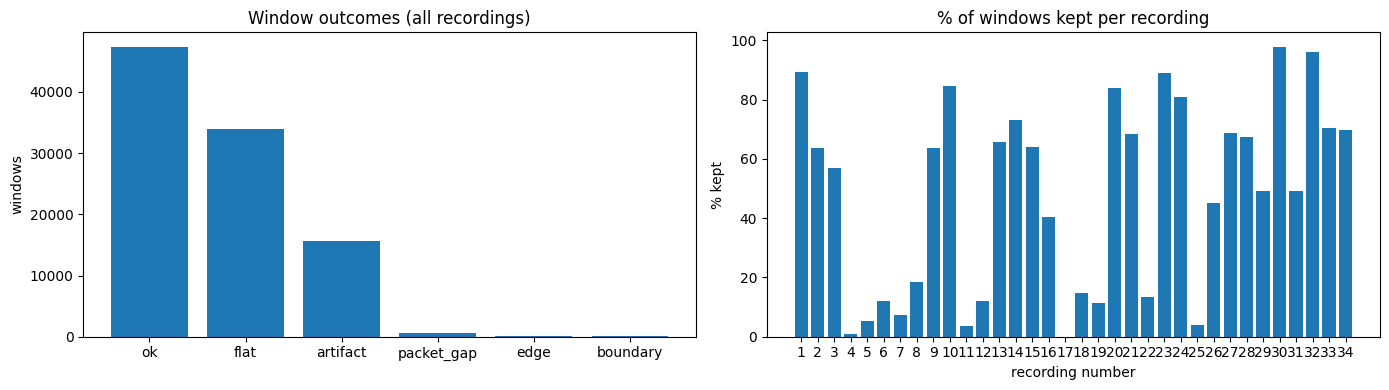

Recordings with the lowest kept fraction (inspect these manually):
rec_num
17    0.0
4     1.0
11    3.5
25    4.1
5     5.4


In [15]:
reason_counts = windows["reason"].value_counts()
print(reason_counts.to_string())

per_rec = windows.groupby("rec_num")["keep"].mean().mul(100)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(reason_counts.index, reason_counts.values)
axes[0].set_title("Window outcomes (all recordings)")
axes[0].set_ylabel("windows")
axes[1].bar(per_rec.index.astype(str), per_rec.values)
axes[1].set_title("% of windows kept per recording")
axes[1].set_xlabel("recording number")
axes[1].set_ylabel("% kept")
plt.tight_layout()
plt.show()

print("Recordings with the lowest kept fraction (inspect these manually):")
print(per_rec.sort_values().head(5).round(1).to_string())

### 8.2 Class balance after cleaning

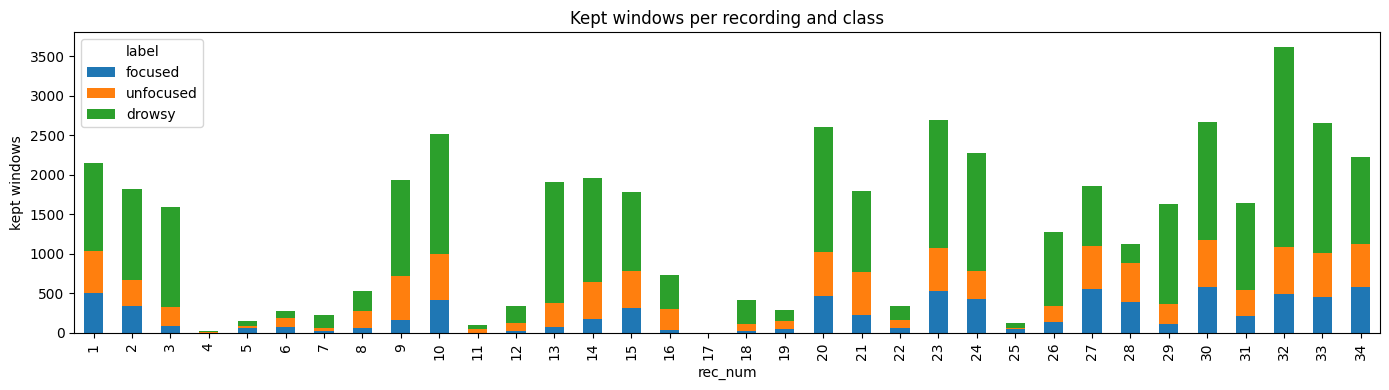

Kept windows per class:
label
drowsy       28883
unfocused    10706
focused       7765

Majority-class share (a trivial baseline accuracy to beat): 61.0%


In [16]:
kept = windows[windows["keep"]]
balance = kept.groupby(["rec_num", "label"]).size().unstack(fill_value=0).rename(columns=LABEL_NAMES)
balance.plot(kind="bar", stacked=True, figsize=(14, 4))
plt.ylabel("kept windows")
plt.title("Kept windows per recording and class")
plt.tight_layout()
plt.show()

total = kept["label"].map(LABEL_NAMES).value_counts()
print("Kept windows per class:")
print(total.to_string())
print("\nMajority-class share (a trivial baseline accuracy to beat):", f"{total.max() / total.sum():.1%}")

## 9. Sanity check: does the cleaned signal differ by class?

Average power spectrum per class over a random sample of kept windows. In drowsiness studies, slow (delta/theta) and alpha
power typically shift relative to the alert state. That is a common expectation, **not a guarantee for this dataset**, so treat
this as a plausibility check, not a test. If the three curves are indistinguishable, something is wrong (labels, channels, or
filtering).

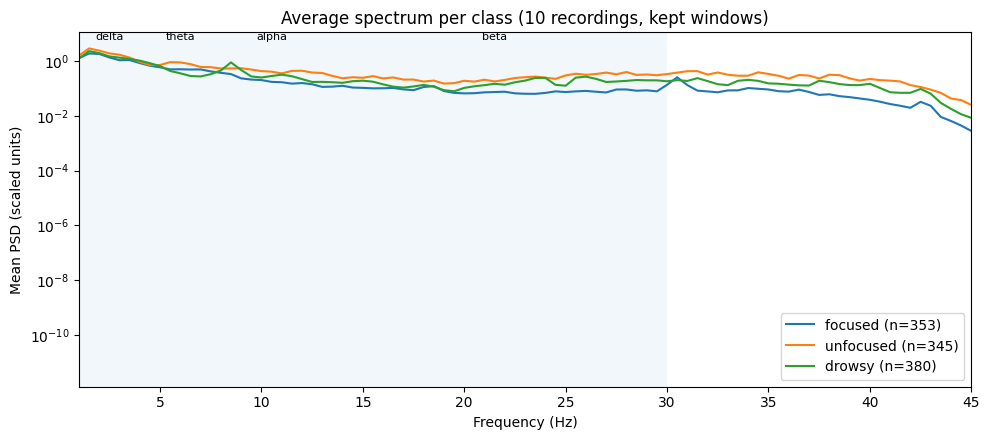

In [17]:
rng = np.random.default_rng(RANDOM_SEED)
win = int(round(WIN_SEC * FS_EXPECTED))
psd_sum = {k: [] for k in LABEL_NAMES}

for path in mat_files[:N_PSD_RECORDINGS]:
    data = np.load(CONT_DIR / f"{path.stem}.npz")
    sig = data["signal"]
    rec_kept = kept[kept["recording"] == path.name]
    for lab in LABEL_NAMES:
        cand = rec_kept[rec_kept["label"] == lab]
        if len(cand) == 0:
            continue
        pick = cand.sample(min(N_PSD_WINDOWS_PER_CLASS, len(cand)), random_state=int(rng.integers(1e9)))
        for s in pick["start"].to_numpy():
            f, p = welch(sig[s:s + win], fs=FS_EXPECTED, nperseg=win, axis=0)
            psd_sum[lab].append(p.mean(axis=1))

fig, ax = plt.subplots(figsize=(10, 4.5))
for lab, name in LABEL_NAMES.items():
    if psd_sum[lab]:
        ax.semilogy(f, np.mean(psd_sum[lab], axis=0), label=f"{name} (n={len(psd_sum[lab])})")
for lo, hi, nm in [(1, 4, "delta"), (4, 8, "theta"), (8, 13, "alpha"), (13, 30, "beta")]:
    ax.axvspan(lo, hi, alpha=0.06)
    ax.text((lo + hi) / 2, ax.get_ylim()[1], nm, ha="center", va="top", fontsize=8)
ax.set_xlim(1, 45)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Mean PSD (scaled units)")
ax.set_title(f"Average spectrum per class ({N_PSD_RECORDINGS} recordings, kept windows)")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Subjects: what we can and cannot say yet

The paper reports **5 participants** across the 34 recordings, but nothing inside the files links a recording to a participant.
The `id` string encodes the session start time (`YYYYMMDDhhmm`) and the EPOC device serial. Below we parse both. This is
*evidence to help you group recordings*, not a mapping.

Until a real mapping exists, `windows.csv` uses `group = recording`. A recording-level split is **better than random windows
but can still leak** if several recordings come from the same person (the model can learn person-specific signal).

,file,num,id,datetime,device_serial,days_since_first
0,eeg_record1.mat,1,201410092013.D091BB44,2014-10-09 20:13:00,D091BB44,0
1,eeg_record2.mat,2,201410101933.D091BB44,2014-10-10 19:33:00,D091BB44,0
2,eeg_record3.mat,3,201410121914.D091BB44,2014-10-12 19:14:00,D091BB44,2
3,eeg_record4.mat,4,201410131955.D091BB44,2014-10-13 19:55:00,D091BB44,3
4,eeg_record5.mat,5,201410211925.D091BB44,2014-10-21 19:25:00,D091BB44,11
5,eeg_record6.mat,6,201411241923.D091BB44,2014-11-24 19:23:00,D091BB44,45
6,eeg_record7.mat,7,201411251929.D091BB44,2014-11-25 19:29:00,D091BB44,46
7,eeg_record8.mat,8,201411272109.D091BB44,2014-11-27 21:09:00,D091BB44,49
8,eeg_record9.mat,9,201411301931.D091BB44,2014-11-30 19:31:00,D091BB44,51
9,eeg_record10.mat,10,201412021859.D091BB44,2014-12-02 18:59:00,D091BB44,53


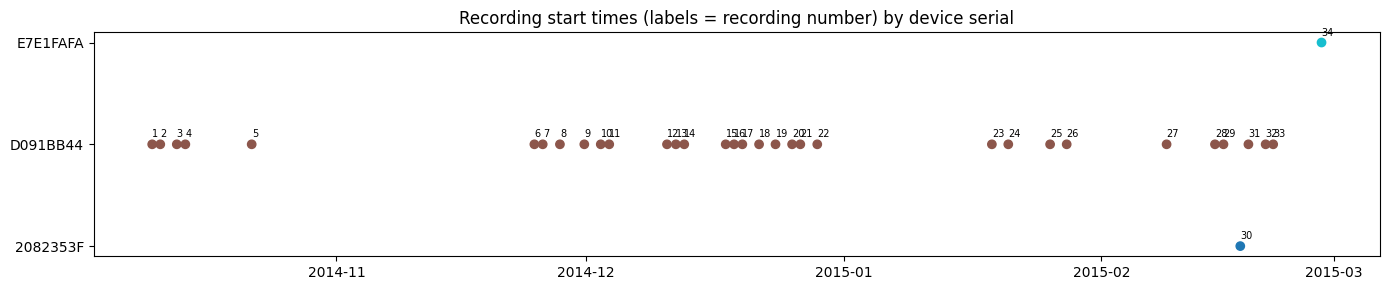

Wrote a template you can fill in: C:\Users\gaida\eeg-attention-deep-learning\data\interim\subject_map_TEMPLATE.csv


In [18]:
ids = qc_df[["file", "num", "id"]].copy()
ids["datetime"] = pd.to_datetime(ids["id"].str[:12], format="%Y%m%d%H%M", errors="coerce")
ids["device_serial"] = ids["id"].str.split(".").str[-1]
ids = ids.sort_values("datetime").reset_index(drop=True)
ids["days_since_first"] = (ids["datetime"] - ids["datetime"].min()).dt.days
display(ids)

serial_codes = ids["device_serial"].astype("category").cat.codes
fig, ax = plt.subplots(figsize=(14, 3))
ax.scatter(ids["datetime"], serial_codes, c=serial_codes, cmap="tab10")
for _, r in ids.iterrows():
    ax.annotate(str(r["num"]), (r["datetime"], serial_codes[_]), fontsize=7, xytext=(0, 5), textcoords="offset points")
ax.set_yticks(sorted(serial_codes.unique()))
ax.set_yticklabels(ids["device_serial"].astype("category").cat.categories)
ax.set_title("Recording start times (labels = recording number) by device serial")
plt.tight_layout()
plt.show()

template = ids[["file", "num", "id", "datetime", "device_serial"]].copy()
template["subject"] = ""          # <- fill this in when you know the mapping
template_path = INTERIM_DIR / "subject_map_TEMPLATE.csv"
template.to_csv(template_path, index=False)
print("Wrote a template you can fill in:", template_path)

**How to resolve the subject question (do not guess):**

1. Check the paper (Aci, Kaya, Mishchenko 2019) and the Kaggle page/discussion for a session-to-participant description.
2. If none exists, you can look for a data-driven hint (for example whether recordings cluster in time), but treat any
   inferred grouping as an **assumption** and state it in your report.
3. Once you have a mapping, save it as `data/interim/subject_map.csv` with columns `file, subject`, and set
   `windows["group"]` from it in notebook 03/04.

## 11. Outputs and what comes next

**Files written**

| File | Content |
|---|---|
| `data/interim/qc_summary.csv` | per-recording QC (duration, packet jumps, interpolation) |
| `data/interim/channel_std_per_recording.csv` | channel std table used for channel selection |
| `data/interim/subject_map_TEMPLATE.csv` | template for the subject mapping |
| `data/processed/continuous/eeg_recordN.npz` | filtered, robust-scaled `signal (n, channels)` float32, per-sample `labels`, `channels`, `fs` |
| `data/processed/windows.csv` | window index: recording, start, end, label, reason, keep, group |
| `data/processed/preprocessing_config.json` | exact parameters used |

**Loading a window later (notebook 03/04):**

```python
d = np.load("data/processed/continuous/eeg_record1.npz")
row = windows[windows.keep].iloc[0]
x = d["signal"][row.start:row.end].T      # (channels, samples)
y = row.label
```

**Limitations to keep in mind**

- Labels are protocol-derived, not verified per participant.
- Subject grouping is unresolved; recording-level splits may still leak.
- Artifact rejection is a simple amplitude rule. No ICA or eye-blink regression was applied.
- The channel selection and every threshold are tunable and should be justified in your report.

**Next:** `03_feature_analysis.ipynb`: band power features per window, class differences, and per-subject/recording variability.